# LM Profesionales — Primera entrega Coderhouse
## Obtención de insights a partir de visualizaciones

**Proyecto:** Gestión comercial, financiera y operativa de un estudio contable.  
**Autor:** Marcos Nahuel Lara — LM Profesionales.  
**Alcance de esta entrega:** análisis exploratorio de datos (EDA), visualizaciones ejecutivas e insights. La construcción y optimización de modelos de Machine Learning se deja para una etapa posterior, una vez que exista una base histórica más amplia y variables operativas suficientes.

### Abstracto, motivación y audiencia
LM Profesionales necesita convertir sus registros de servicios en información útil para decidir: qué servicios generan más ingresos, dónde se concentra la actividad, qué márgenes se observan y qué proporción de los trabajos figura como pendiente o en proceso. El análisis está dirigido a la dirección del estudio y a quienes coordinan la operación y el desarrollo comercial.

La base contiene registros de servicios, no estados contables completos. Por eso, el campo **Ganancia** se interpreta como contribución registrada (= Importe − Costo), no como resultado neto del estudio. La moneda no está especificada en el archivo y se conserva la unidad monetaria original.


## 1. Preguntas e hipótesis

1. ¿Cuál es el volumen total de importes, costos y ganancia registrada?
2. ¿Qué servicios aportan más importe y cuáles muestran mayor margen registrado?
3. ¿Qué localidades concentran actividad y dónde se observan diferencias de margen?
4. ¿Cómo se distribuyen los servicios según su estado operativo?
5. ¿Existe concentración de los importes en pocos clientes?
6. ¿La base presenta faltantes, duplicados o inconsistencias en el cálculo de Ganancia?

**Hipótesis iniciales:** auditoría y consultoría podrían liderar el importe; las diferencias por localidad podrían señalar oportunidades de eficiencia; y una proporción alta de tareas no finalizadas justificaría un seguimiento operativo más sistemático.


## 2. Importación de datos

La fuente principal es la base operativa de LM Profesionales provista para el proyecto y exportada a CSV. Se distribuye una copia anonimizada: el nombre de cada cliente fue reemplazado por una etiqueta construida a partir de su ID.

Además, se incorpora una consulta a la **API pública Georef de Datos Argentina** para normalizar/enriquecer la dimensión geográfica con nombres oficiales y, cuando la API los devuelve, centroides. Este enriquecimiento es complementario: los indicadores financieros se calculan exclusivamente a partir de la base operativa.

Fuentes:
- Base operativa: archivo aportado por LM Profesionales para esta entrega.
- API Georef: https://apis.datos.gob.ar/georef/api (documentación: https://www.argentina.gob.ar/georef)


In [1]:
from pathlib import Path
import re
import unicodedata
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Buscar el CSV tanto al ejecutar desde /notebooks como desde la raíz del repositorio.
candidates = [
    Path("../data/01_base_lm_anonimizada.csv"),
    Path("data/01_base_lm_anonimizada.csv"),
    Path("01_base_lm_anonimizada.csv"),
    Path("LM_Profesionales_Coderhouse/data/01_base_lm_anonimizada.csv"),
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    matches = list(Path.cwd().rglob("01_base_lm_anonimizada.csv"))
    DATA_PATH = matches[0] if matches else None

if DATA_PATH is None:
    # Alternativa para Google Colab cuando se sube el notebook sin clonar el repositorio.
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_uploaded = next((name for name in uploaded if name.lower().endswith(".csv")), None)
        if csv_uploaded is None:
            raise FileNotFoundError("No se encontró un archivo CSV entre los archivos subidos.")
        DATA_PATH = Path(csv_uploaded)
    except ImportError as exc:
        raise FileNotFoundError(
            "No se encontró el CSV. Ejecutá el notebook desde el repositorio o subí "
            "data/01_base_lm_anonimizada.csv."
        ) from exc

df_raw = pd.read_csv(DATA_PATH)
print(f"Archivo cargado: {DATA_PATH}")
print(f"Dimensiones originales: {df_raw.shape[0]} filas × {df_raw.shape[1]} columnas")
display(df_raw.head())


Archivo cargado: data/01_base_lm_anonimizada.csv
Dimensiones originales: 100 filas × 9 columnas


,Fecha,ID Cliente,Cliente,Localidad,Servicio,Estado,Importe,Costo,Ganancia
0,2025-07-14,CL024,Cliente CL024,San Pedro,Certificación de Ingresos,En Proceso,164979,56093,108886
1,2026-05-25,CL018,Cliente CL018,Libertador Gral. San Martín,Liquidación de Sueldos,Finalizado,90382,17173,73209
2,2025-08-25,CL023,Cliente CL023,Perico,Liquidación IVA,En Proceso,129256,58165,71091
3,2024-03-24,CL057,Cliente CL057,Perico,Liquidación IVA,Finalizado,115979,40593,75386
4,2025-05-21,CL011,Cliente CL011,Perico,Consultoría Impositiva,Pendiente,170628,69957,100671


In [2]:
# Consulta opcional a la API pública Georef: localidades de Jujuy.
# La consulta está protegida para que el análisis principal pueda continuar si el servicio no responde.
GEOREF_URL = "https://apis.datos.gob.ar/georef/api/localidades"
geo_df = pd.DataFrame(columns=["Localidad_API", "lat", "lon"])

try:
    response = requests.get(
        GEOREF_URL,
        params={"provincia": "Jujuy", "max": 5000, "campos": "estandar"},
        timeout=25
    )
    response.raise_for_status()
    payload = response.json()
    localidades = payload.get("localidades", [])

    geo_rows = []
    for item in localidades:
        centroide = item.get("centroide") or {}
        geo_rows.append({
            "Localidad_API": item.get("nombre"),
            "lat": centroide.get("lat"),
            "lon": centroide.get("lon"),
            "Provincia_API": (item.get("provincia") or {}).get("nombre")
        })

    geo_df = pd.DataFrame(geo_rows)
    geo_df.to_csv("02_georef_localidades_jujuy.csv", index=False, encoding="utf-8-sig")
    print(f"API Georef consultada correctamente: {len(geo_df)} localidades recibidas.")
except Exception as e:
    print("No fue posible consultar Georef en esta ejecución.")
    print(f"Detalle: {type(e).__name__}: {e}")
    print("El EDA financiero continúa con la base local; el enriquecimiento geográfico queda pendiente.")

display(geo_df.head())


No fue posible consultar Georef en esta ejecución.
Detalle: ConnectionError: HTTPSConnectionPool(host='apis.datos.gob.ar', port=443): Max retries exceeded with url: /georef/api/localidades?provincia=Jujuy&max=5000&campos=estandar (Caused by NameResolutionError("HTTPSConnection(host='apis.datos.gob.ar', port=443): Failed to resolve 'apis.datos.gob.ar' ([Errno -3] Temporary failure in name resolution)"))
El EDA financiero continúa con la base local; el enriquecimiento geográfico queda pendiente.


,Localidad_API,lat,lon


## 3. Limpieza y transformación

Se normalizan fechas y categorías, se convierten los importes a formato numérico, se revisan valores nulos y duplicados y se recalcula Ganancia para validar la consistencia de la variable provista.

La repetición de un mismo ID Cliente es esperable porque un cliente puede contratar más de un servicio; no se considera duplicidad por sí sola.


In [3]:
df = df_raw.copy()

required_columns = [
    "Fecha", "ID Cliente", "Cliente", "Localidad", "Servicio",
    "Estado", "Importe", "Costo", "Ganancia"
]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Faltan columnas requeridas: {missing_columns}")

# Tipos
df["Fecha"] = pd.to_datetime(df["Fecha"], errors="coerce")
for col in ["ID Cliente", "Cliente", "Localidad", "Servicio", "Estado"]:
    df[col] = df[col].astype("string").str.strip()
for col in ["Importe", "Costo", "Ganancia"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Variables derivadas
df["Ganancia_calculada"] = df["Importe"] - df["Costo"]
df["Diferencia_Ganancia"] = df["Ganancia"] - df["Ganancia_calculada"]
df["Margen"] = np.where(df["Importe"] != 0, df["Ganancia"] / df["Importe"], np.nan)
df["Año"] = df["Fecha"].dt.year
df["Mes"] = df["Fecha"].dt.to_period("M").astype("string")

# Resumen de calidad
quality = pd.DataFrame({
    "Indicador": [
        "Filas", "Columnas originales", "Valores faltantes",
        "Filas duplicadas exactas", "IDs de cliente únicos",
        "Diferencias en Ganancia (Ganancia ≠ Importe − Costo)"
    ],
    "Resultado": [
        len(df), len(df_raw.columns), int(df.isna().sum().sum()),
        int(df.duplicated().sum()), int(df["ID Cliente"].nunique()),
        int((df["Diferencia_Ganancia"].abs() > 0.01).sum())
    ]
})
display(quality)


,Indicador,Resultado
0,Filas,100
1,Columnas originales,9
2,Valores faltantes,0
3,Filas duplicadas exactas,0
4,IDs de cliente únicos,50
5,Diferencias en Ganancia (Ganancia ≠ Importe − ...,0


In [4]:
# Metadata y estadística descriptiva
metadata = pd.DataFrame({
    "Columna": df_raw.columns,
    "Tipo detectado": [str(df_raw[c].dtype) for c in df_raw.columns],
    "Valores únicos": [df_raw[c].nunique(dropna=True) for c in df_raw.columns],
    "Nulos": [int(df_raw[c].isna().sum()) for c in df_raw.columns]
})
display(metadata)

print("Período observado:", df["Fecha"].min().date(), "a", df["Fecha"].max().date())
display(df[["Importe", "Costo", "Ganancia", "Margen"]].describe().round(3))


,Columna,Tipo detectado,Valores únicos,Nulos
0,Fecha,object,98,0
1,ID Cliente,object,50,0
2,Cliente,object,50,0
3,Localidad,object,7,0
4,Servicio,object,7,0
5,Estado,object,3,0
6,Importe,int64,100,0
7,Costo,int64,100,0
8,Ganancia,int64,100,0


Período observado: 2024-01-11 a 2026-06-26


,Importe,Costo,Ganancia,Margen
count,100.000,100.000,100.000,100.000
mean,152392.700,47028.870,105363.830,0.691
std,68827.237,24963.039,50784.968,0.087
min,50027.000,10005.000,30249.000,0.550
25%,106722.750,28449.250,70863.500,0.610
50%,140917.000,41667.000,93978.000,0.690
75%,178143.250,58238.000,125088.250,0.770
max,361970.000,126795.000,257235.000,0.840


## 4. Indicadores generales

**Interpretación:** el campo Ganancia se conserva como una medida registrada de importe menos costo directo informado. Sin información sobre gastos generales, impuestos, remuneraciones del titular u otros costos indirectos, no corresponde interpretarlo como utilidad neta contable.


In [5]:
total_importe = df["Importe"].sum()
total_costo = df["Costo"].sum()
total_ganancia = df["Ganancia"].sum()
margen_global = total_ganancia / total_importe
ticket_promedio = df["Importe"].mean()
clientes_unicos = df["ID Cliente"].nunique()

kpis = pd.DataFrame({
    "Indicador": [
        "Importe total", "Costo total", "Ganancia registrada",
        "Margen registrado", "Ticket promedio", "Clientes únicos", "Registros"
    ],
    "Valor": [
        total_importe, total_costo, total_ganancia,
        margen_global, ticket_promedio, clientes_unicos, len(df)
    ]
})
display(kpis)


,Indicador,Valor
0,Importe total,1.523927e+07
1,Costo total,4.702887e+06
2,Ganancia registrada,1.053638e+07
3,Margen registrado,6.913968e-01
4,Ticket promedio,1.523927e+05
5,Clientes únicos,5.000000e+01
6,Registros,1.000000e+02


## 5. Análisis por servicio

,Servicio,Registros,Importe,Costo,Ganancia,Margen
1,Auditoría,13,"3,269,820","952,634","2,317,186",70.9%
3,Consultoría Impositiva,12,"2,877,556","936,089","1,941,467",67.5%
6,Liquidación de Sueldos,14,"1,948,650","651,708","1,296,942",66.6%
2,Certificación de Ingresos,13,"1,932,463","580,696","1,351,767",70.0%
4,Inscripción ARCA,19,"1,896,405","526,659","1,369,746",72.2%
5,Liquidación IVA,13,"1,849,166","595,227","1,253,939",67.8%
0,Alta Monotributo,16,"1,465,210","459,874","1,005,336",68.6%


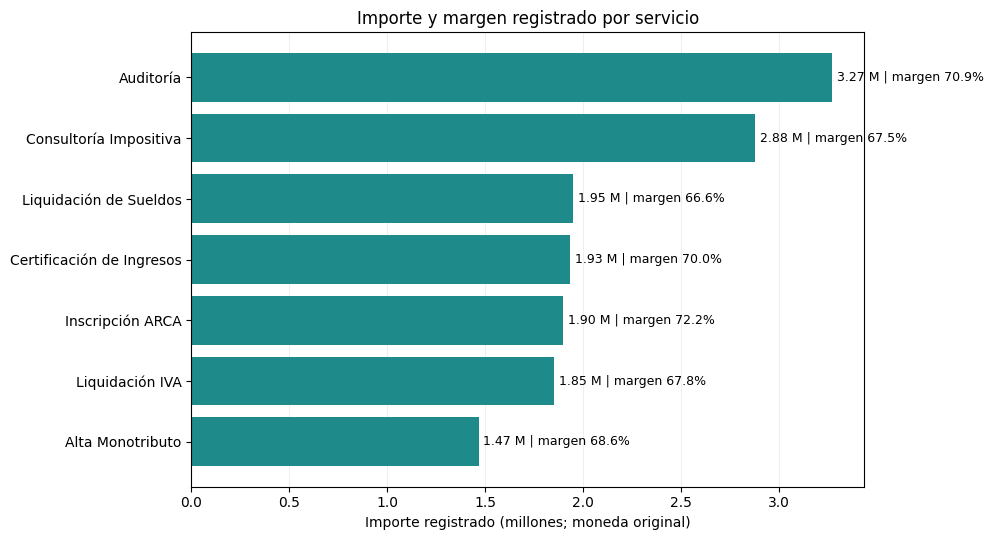

In [6]:
by_service = (
    df.groupby("Servicio", as_index=False)
      .agg(Registros=("Servicio", "size"),
           Importe=("Importe", "sum"),
           Costo=("Costo", "sum"),
           Ganancia=("Ganancia", "sum"))
)
by_service["Margen"] = by_service["Ganancia"] / by_service["Importe"]
by_service = by_service.sort_values("Importe", ascending=False)
display(by_service.style.format({
    "Importe": "{:,.0f}", "Costo": "{:,.0f}",
    "Ganancia": "{:,.0f}", "Margen": "{:.1%}"
}))

plt.figure(figsize=(10, 5.5))
plot_df = by_service.sort_values("Importe")
plt.barh(plot_df["Servicio"], plot_df["Importe"] / 1_000_000, color="#1F8A8A")
for y, (_, row) in enumerate(plot_df.iterrows()):
    plt.text(row["Importe"]/1_000_000 + 0.025, y,
             f'{row["Importe"]/1_000_000:.2f} M | margen {row["Margen"]:.1%}',
             va="center", fontsize=9)
plt.xlabel("Importe registrado (millones; moneda original)")
plt.title("Importe y margen registrado por servicio")
plt.grid(axis="x", alpha=.2)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()


## 6. Análisis por localidad

,Localidad,Registros,Importe,Costo,Ganancia,Margen
5,San Salvador de Jujuy,18,"2,750,770","855,615","1,895,155",68.9%
3,Perico,15,"2,571,445","892,049","1,679,396",65.3%
4,San Pedro,19,"2,413,364","707,673","1,705,691",70.7%
6,Tilcara,16,"2,245,476","631,540","1,613,936",71.9%
2,Palpalá,13,"1,965,345","629,436","1,335,909",68.0%
0,Humahuaca,8,"1,659,178","494,106","1,165,072",70.2%
1,Libertador Gral. San Martín,11,"1,633,692","492,468","1,141,224",69.9%


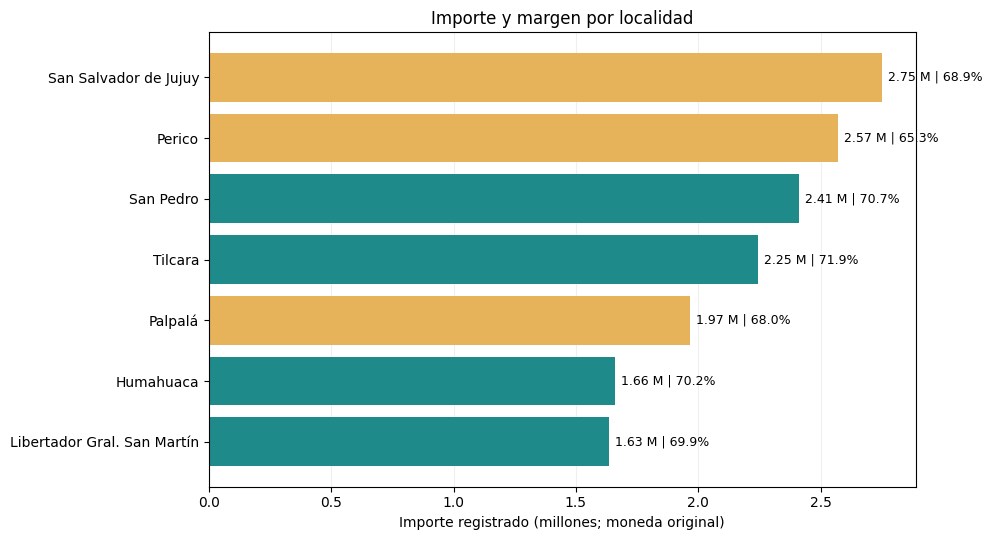

In [7]:
by_locality = (
    df.groupby("Localidad", as_index=False)
      .agg(Registros=("Localidad", "size"),
           Importe=("Importe", "sum"),
           Costo=("Costo", "sum"),
           Ganancia=("Ganancia", "sum"))
)
by_locality["Margen"] = by_locality["Ganancia"] / by_locality["Importe"]
by_locality = by_locality.sort_values("Importe", ascending=False)
display(by_locality.style.format({
    "Importe": "{:,.0f}", "Costo": "{:,.0f}",
    "Ganancia": "{:,.0f}", "Margen": "{:.1%}"
}))

plt.figure(figsize=(10, 5.5))
plot_df = by_locality.sort_values("Importe")
colors = ["#1F8A8A" if x >= 0.69 else "#E6B35A" for x in plot_df["Margen"]]
plt.barh(plot_df["Localidad"], plot_df["Importe"] / 1_000_000, color=colors)
for y, (_, row) in enumerate(plot_df.iterrows()):
    plt.text(row["Importe"]/1_000_000 + 0.025, y,
             f'{row["Importe"]/1_000_000:.2f} M | {row["Margen"]:.1%}',
             va="center", fontsize=9)
plt.xlabel("Importe registrado (millones; moneda original)")
plt.title("Importe y margen por localidad")
plt.grid(axis="x", alpha=.2)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()


## 7. Estado operativo

,Estado,Registros,Importe,Ganancia,Participación de registros
0,En Proceso,35,"5,100,230","3,547,273",35.0%
1,Finalizado,33,"4,803,532","3,385,674",33.0%
2,Pendiente,32,"5,335,508","3,603,436",32.0%


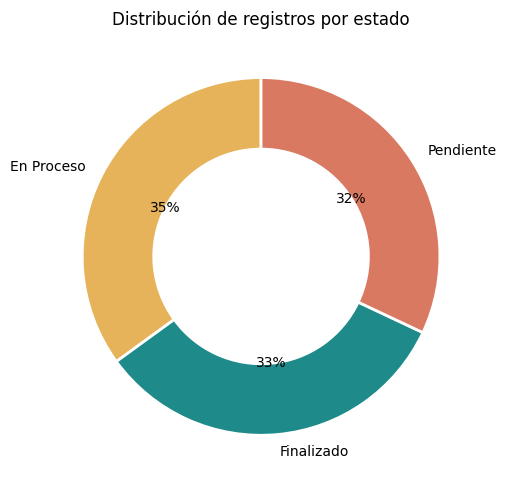

Registros no finalizados: 67 de 100 (67.0%)
Importe asociado a registros no finalizados: 10,435,738 (68.5% del importe registrado).


In [8]:
by_status = (
    df.groupby("Estado", as_index=False)
      .agg(Registros=("Estado", "size"),
           Importe=("Importe", "sum"),
           Ganancia=("Ganancia", "sum"))
)
by_status["Participación de registros"] = by_status["Registros"] / len(df)
display(by_status.style.format({
    "Importe": "{:,.0f}", "Ganancia": "{:,.0f}",
    "Participación de registros": "{:.1%}"
}))

status_counts = df["Estado"].value_counts()
plt.figure(figsize=(6.2, 5))
plt.pie(
    status_counts.values,
    labels=status_counts.index,
    autopct="%1.0f%%",
    startangle=90,
    colors=["#E6B35A", "#1F8A8A", "#D97962"],
    wedgeprops={"width": 0.4, "edgecolor": "white", "linewidth": 2}
)
plt.title("Distribución de registros por estado")
plt.tight_layout()
plt.show()

no_finalizados = df[df["Estado"] != "Finalizado"]
print(f"Registros no finalizados: {len(no_finalizados)} de {len(df)} ({len(no_finalizados)/len(df):.1%})")
print(f"Importe asociado a registros no finalizados: {no_finalizados['Importe'].sum():,.0f} "
      f"({no_finalizados['Importe'].sum()/total_importe:.1%} del importe registrado).")


## 8. Concentración de clientes

,ID Cliente,Cliente,Registros,Importe,Ganancia
42,CL052,Cliente CL052,4,"798,813","534,557"
25,CL032,Cliente CL032,5,"677,767","444,134"
13,CL017,Cliente CL017,5,"634,291","405,962"
21,CL026,Cliente CL026,3,"609,254","421,409"
2,CL003,Cliente CL003,4,"590,438","447,473"
11,CL015,Cliente CL015,3,"589,497","454,907"
40,CL050,Cliente CL050,3,"587,138","435,736"
41,CL051,Cliente CL051,3,"558,906","349,347"
20,CL025,Cliente CL025,4,"533,803","366,099"
22,CL027,Cliente CL027,2,"500,566","365,964"


Participación de los 5 principales clientes: 21.7%
Participación de los 10 principales clientes: 39.9%


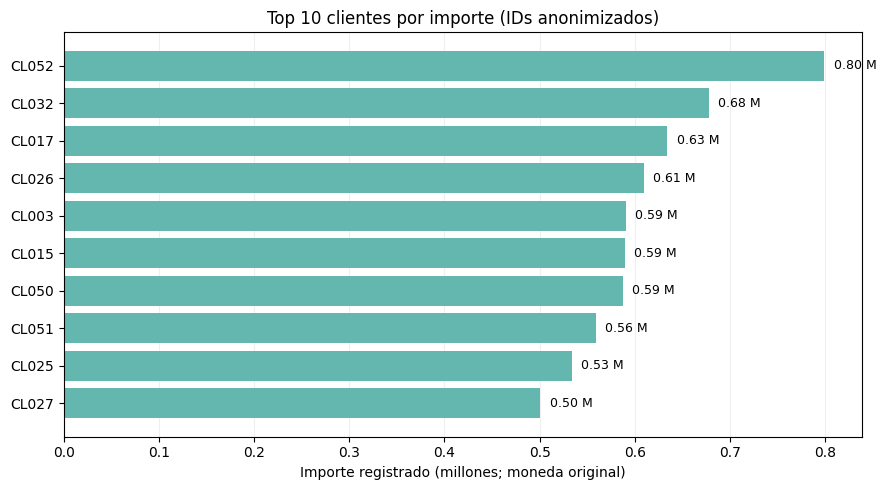

In [9]:
by_client = (
    df.groupby(["ID Cliente", "Cliente"], as_index=False)
      .agg(Registros=("ID Cliente", "size"),
           Importe=("Importe", "sum"),
           Ganancia=("Ganancia", "sum"))
)
by_client = by_client.sort_values("Importe", ascending=False)
top10 = by_client.head(10).copy()
top5_share = by_client.head(5)["Importe"].sum() / total_importe
top10_share = top10["Importe"].sum() / total_importe

display(top10.style.format({
    "Importe": "{:,.0f}", "Ganancia": "{:,.0f}"
}))
print(f"Participación de los 5 principales clientes: {top5_share:.1%}")
print(f"Participación de los 10 principales clientes: {top10_share:.1%}")

plt.figure(figsize=(9, 5))
plot_df = top10.sort_values("Importe")
plt.barh(plot_df["ID Cliente"], plot_df["Importe"] / 1_000_000, color="#63B7AF")
for y, (_, row) in enumerate(plot_df.iterrows()):
    plt.text(row["Importe"]/1_000_000 + .01, y,
             f'{row["Importe"]/1_000_000:.2f} M', va="center", fontsize=9)
plt.xlabel("Importe registrado (millones; moneda original)")
plt.title("Top 10 clientes por importe (IDs anonimizados)")
plt.grid(axis="x", alpha=.2)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()


## 9. Insights ejecutivos

- **Escala y contribución:** el conjunto registra un importe total de 15.239.270 y una ganancia registrada de 10.536.383; el margen agregado es 69,1%.
- **Servicios:** Auditoría es el servicio con mayor importe acumulado (3.269.820; 21,5% del total). Inscripción ARCA presenta el mayor margen registrado entre los servicios (72,2%).
- **Localidades:** San Salvador de Jujuy concentra el mayor importe (2.750.770). Tilcara exhibe el margen más alto (71,9%), mientras Perico registra el más bajo (65,3%).
- **Operación:** 67 de 100 registros no figuran como finalizados. El importe asociado a esos registros representa cerca del 68,5% del total; esto no equivale a deuda ni a facturación pendiente de cobro.
- **Clientes:** los 10 principales concentran 39,9% del importe, por lo que la cartera no depende exclusivamente de uno o dos clientes, aunque conviene monitorear la concentración.
- **Calidad:** no se detectan nulos ni diferencias entre Ganancia e Importe menos Costo en los 100 registros de la muestra.

### Cautelas de interpretación
El período cubre del 11/01/2024 al 26/06/2026; 2026 es parcial y no debe compararse como año completo. La base no contiene fecha de inicio/cierre, horas trabajadas, fecha de cobro, gastos indirectos ni moneda. Por eso, los estados permiten describir una distribución, pero no medir antigüedad de pendientes, demoras ni rentabilidad neta.


## 10. Recomendaciones y continuidad hacia Machine Learning

1. **Gestión operativa:** agregar fecha de alta, fecha comprometida y fecha de finalización; construir antigüedad de pendientes y alertas por vencimiento.
2. **Rentabilidad por servicio:** registrar horas profesionales, costos directos e indirectos y cobros efectivamente percibidos.
3. **Gestión comercial:** registrar canal de adquisición, consultas, presupuestos, conversiones y clientes nuevos/recurrentes.
4. **Enriquecimiento geográfico:** conservar códigos y coordenadas devueltos por Georef para analizar cobertura territorial.
5. **Próxima etapa ML:** con una serie histórica ampliada, evaluar modelos para pronosticar demanda por servicio, anticipar carga operativa o detectar servicios/clientes con margen atípico. La muestra actual de 100 registros no alcanza para sostener un modelo predictivo robusto.

**Conclusión:** el EDA muestra una contribución registrada relevante, una cartera diversificada y un conjunto importante de servicios que aún figuran sin finalizar. La prioridad es mejorar trazabilidad y tiempos operativos para pasar de un tablero descriptivo a decisiones predictivas confiables.
